<a href="https://colab.research.google.com/github/MBR4V0/Python/blob/main/2Modelo_XGBost_Multi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip install pandas numpy faker openpyxl seaborn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 21.4 MB/s eta 0:00:00


In [3]:
!pip install -q xgboost

In [4]:
# ==========================================================
# INSTALAÇÃO
# ==========================================================

!pip install -q pandas numpy faker openpyxl


# ==========================================================
# IMPORTAÇÕES
# ==========================================================

import pandas as pd
import numpy as np
import random

from faker import Faker


# ==========================================================
# CONFIGURAÇÕES
# ==========================================================

fake = Faker("pt_BR")

# Permite reproduzir os mesmos dados
random.seed(42)
np.random.seed(42)
Faker.seed(42)

quantidade = 2000


# ==========================================================
# LISTAS
# ==========================================================

produtos = [
    "Computador",
    "Bicicleta",
    "Celular",
    "Automóvel",
    "Notebook"
]

cidades = [
    "São Paulo",
    "Rio de Janeiro",
    "Belo Horizonte",
    "Curitiba",
    "Porto Alegre",
    "Salvador",
    "Brasília",
    "Recife",
    "Fortaleza",
    "Campinas"
]

sexos = [
    "Masculino",
    "Feminino"
]

formas_pagamento = [
    "Cartão de Crédito",
    "Cartão de Débito",
    "PIX",
    "Boleto"
]


# ==========================================================
# FAIXAS DE PREÇO
# ==========================================================

valores = {
    "Computador": (2500, 8000),
    "Bicicleta": (800, 6000),
    "Celular": (800, 7000),
    "Automóvel": (30000, 150000),
    "Notebook": (2000, 12000)
}


# ==========================================================
# FUNÇÃO QUE DEFINE O PRODUTO
# ==========================================================
#
# Existe uma relação INTENCIONAL entre idade e produto.
#
# 18 - 25  -> Celular
# 26 - 35  -> Notebook
# 36 - 50  -> Computador
# 51 - 75  -> Automóvel
#
# Também existe influência da cidade.
#
# 90% dos casos seguem o padrão principal.
# 10% são aleatórios para introduzir ruído.
#
# ==========================================================

def escolher_produto(idade, cidade):

    # ------------------------------------------------------
    # PRODUTO PRINCIPAL BASEADO NA IDADE
    # ------------------------------------------------------

    if idade <= 25:

        produto_principal = "Celular"

    elif idade <= 35:

        produto_principal = "Notebook"

    elif idade <= 50:

        produto_principal = "Computador"

    else:

        produto_principal = "Automóvel"


    # ------------------------------------------------------
    # INFLUÊNCIA DA CIDADE
    # ------------------------------------------------------

    # São Paulo e Brasília
    # aumentam a preferência por Automóvel

    if cidade in ["São Paulo", "Brasília"]:

        if random.random() < 0.25:
            produto_principal = "Automóvel"


    # Curitiba e Porto Alegre
    # aumentam a preferência por Bicicleta

    elif cidade in ["Curitiba", "Porto Alegre"]:

        if random.random() < 0.25:
            produto_principal = "Bicicleta"


    # Rio, Salvador, Recife e Fortaleza
    # aumentam a preferência por Celular

    elif cidade in [
        "Rio de Janeiro",
        "Salvador",
        "Recife",
        "Fortaleza"
    ]:

        if random.random() < 0.25:
            produto_principal = "Celular"


    # Belo Horizonte e Campinas
    # aumentam a preferência por Computador

    elif cidade in [
        "Belo Horizonte",
        "Campinas"
    ]:

        if random.random() < 0.25:
            produto_principal = "Computador"


    # ------------------------------------------------------
    # RUÍDO
    # ------------------------------------------------------
    #
    # 10% dos registros recebem um produto aleatório.
    #
    # Isso evita que o dataset seja 100% determinístico.
    #
    # ------------------------------------------------------

    if random.random() < 0.10:

        produto_principal = random.choice(produtos)


    return produto_principal


# ==========================================================
# CRIAÇÃO DOS DADOS
# ==========================================================

dados = []


for i in range(quantidade):

    # ------------------------------------------------------
    # DADOS DO CLIENTE
    # ------------------------------------------------------

    idade = random.randint(18, 75)

    sexo = random.choice(sexos)

    cidade = random.choice(cidades)


    # ------------------------------------------------------
    # PRODUTO
    # ------------------------------------------------------

    produto = escolher_produto(
        idade,
        cidade
    )


    # ------------------------------------------------------
    # VALOR DA COMPRA
    # ------------------------------------------------------

    valor_minimo, valor_maximo = valores[produto]

    valor = round(
        random.uniform(
            valor_minimo,
            valor_maximo
        ),
        2
    )


    # ------------------------------------------------------
    # FORMA DE PAGAMENTO
    # ------------------------------------------------------

    forma_pagamento = random.choice(
        formas_pagamento
    )


    # ------------------------------------------------------
    # DATA DA COMPRA
    # ------------------------------------------------------

    data_compra = fake.date_between(
        start_date="-3y",
        end_date="today"
    )


    # ------------------------------------------------------
    # REGISTRO
    # ------------------------------------------------------

    dados.append({

        "id_cliente": 1001 + i,

        "nome": fake.name(),

        "cpf_ficticio": fake.cpf(),

        "data_compra": data_compra,

        "idade": idade,

        "sexo": sexo,

        "cidade": cidade,

        "item_compra": produto,

        "valor_compra": valor,

        "forma_pagamento": forma_pagamento
    })


# ==========================================================
# DATAFRAME
# ==========================================================

df = pd.DataFrame(dados)


# ==========================================================
# SALVAR EXCEL
# ==========================================================

df.to_excel(
    "clientes_2000_registros.xlsx",
    index=False
)


# ==========================================================
# SALVAR CSV
# ==========================================================

df.to_csv(
    "clientes_2000_registros.csv",
    index=False,
    encoding="utf-8-sig"
)


# ==========================================================
# VERIFICAÇÃO DO DATASET
# ==========================================================

print("=" * 60)
print("DATASET CRIADO COM SUCESSO")
print("=" * 60)

print("\nQuantidade de registros:")
print(len(df))

print("\nDimensão:")
print(df.shape)

print("\nPrimeiros registros:")
print(df.head())


# ==========================================================
# DISTRIBUIÇÃO DOS PRODUTOS
# ==========================================================

print("\n" + "=" * 60)
print("DISTRIBUIÇÃO DOS PRODUTOS")
print("=" * 60)

print(
    df["item_compra"].value_counts()
)

print("\nPercentual:")

print(
    df["item_compra"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ==========================================================
# IDADE MÉDIA POR PRODUTO
# ==========================================================

print("\n" + "=" * 60)
print("IDADE MÉDIA POR PRODUTO")
print("=" * 60)

print(
    df.groupby("item_compra")["idade"]
    .mean()
    .round(2)
)


# ==========================================================
# RELAÇÃO IDADE X PRODUTO
# ==========================================================

print("\n" + "=" * 60)
print("RELAÇÃO ENTRE IDADE E PRODUTO")
print("=" * 60)

faixas = pd.cut(
    df["idade"],
    bins=[17, 25, 35, 50, 60, 75]
)

tabela_idade = pd.crosstab(
    faixas,
    df["item_compra"],
    normalize="index"
) * 100

print(
    tabela_idade.round(2)
)


# ==========================================================
# RELAÇÃO CIDADE X PRODUTO
# ==========================================================

print("\n" + "=" * 60)
print("RELAÇÃO ENTRE CIDADE E PRODUTO")
print("=" * 60)

tabela_cidade = pd.crosstab(
    df["cidade"],
    df["item_compra"],
    normalize="index"
) * 100

print(
    tabela_cidade.round(2)
)


# ==========================================================
# TESTE ESPECÍFICO
# ==========================================================

print("\n" + "=" * 60)
print("TESTE: HOMEM, 30 ANOS, SÃO PAULO")
print("=" * 60)

print(
    "Perfil criado:"
)

print("Idade : 30")
print("Sexo  : Masculino")
print("Cidade: São Paulo")

print(
    "\nO produto esperado para essa faixa etária é:"
)

print("Notebook")


print("\n" + "=" * 60)
print("ARQUIVOS SALVOS")
print("=" * 60)

print("clientes_2000_registros.csv")
print("clientes_2000_registros.xlsx")


DATASET CRIADO COM SUCESSO

Quantidade de registros:
2000

Dimensão:
(2000, 10)

Primeiros registros:
   id_cliente                     nome    cpf_ficticio data_compra  idade  \
0        1001   João Guilherme da Cruz  321.564.087-26  2025-08-08     58   
1        1002    Henrique da Conceição  803.564.791-10  2023-10-12     61   
2        1003          Emanuel Sampaio  654.192.038-98  2025-06-14     53   
3        1004     Dr. Augusto Siqueira  781.304.269-78  2023-12-23     66   
4        1005  Srta. Ana Clara Ribeiro  341.670.952-70  2025-06-01     24   

        sexo     cidade item_compra  valor_compra    forma_pagamento  
0  Masculino  São Paulo   Automóvel      46744.55  Cartão de Crédito  
1  Masculino   Campinas   Bicicleta       2009.84  Cartão de Crédito  
2  Masculino  Fortaleza   Automóvel      63382.88  Cartão de Crédito  
3  Masculino   Brasília   Automóvel     144865.57                PIX  
4  Masculino   Brasília   Automóvel     102447.12  Cartão de Crédito  

DISTRIBU

Criação do XGBost para primeira analise

In [37]:
# ==========================================================
# 1. CARREGAR DADOS
# ==========================================================

import pandas as pd

df = pd.read_csv('/content/clientes_2000_registros.csv')

print("Dimensão original:", df.shape)


Dimensão original: (2000, 10)


In [38]:
# ==========================================================
# 2. LIMPEZA
# ==========================================================

print("Valores ausentes:")
print(df.isnull().sum())

print("\nDuplicatas:", df.duplicated().sum())

df_limpo = df.drop_duplicates().copy()

print("\nDimensão após remoção de duplicatas:", df_limpo.shape)

Valores ausentes:
id_cliente         0
nome               0
cpf_ficticio       0
data_compra        0
idade              0
sexo               0
cidade             0
item_compra        0
valor_compra       0
forma_pagamento    0
dtype: int64

Duplicatas: 0

Dimensão após remoção de duplicatas: (2000, 10)


Homem, 30 anos, São Paulo → qual produto provavelmente comprará?

In [39]:
# ==========================================================
# MODELO - SOMENTE IDADE, SEXO E CIDADE
# ==========================================================

features = [
    'idade',
    'sexo',
    'cidade'
]

X = df_limpo[features].copy()

y = df_limpo['item_compra'].copy()

print("Variáveis utilizadas:")
print(X.columns)

print("\nX:", X.shape)
print("y:", y.shape)

Variáveis utilizadas:
Index(['idade', 'sexo', 'cidade'], dtype='object')

X: (2000, 3)
y: (2000,)


In [40]:
# ==========================================================
# ONE-HOT ENCODING
# ==========================================================

X = pd.get_dummies(
    X,
    columns=['sexo', 'cidade'],
    drop_first=True
)

print("\nX após encoding:")
print(X.shape)



X após encoding:
(2000, 11)


In [41]:
# ==========================================================
# TREINO / TESTE
# ==========================================================

from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=45,
    stratify=y
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)


Treino: (1600, 11)
Teste: (400, 11)


In [42]:
# ==========================================================
# LABEL ENCODER
# ==========================================================

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_treino_encoded = le.fit_transform(y_treino)
y_teste_encoded = le.transform(y_teste)

print("\nClasses:")
print(le.classes_)



Classes:
['Automóvel' 'Bicicleta' 'Celular' 'Computador' 'Notebook']


In [43]:
# ==========================================================
# XGBOOST
# ==========================================================

from xgboost import XGBClassifier

modelo_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=2,
    learning_rate=0.05,
    random_state=45,
    eval_metric='mlogloss'
)

modelo_xgb.fit(
    X_treino,
    y_treino_encoded
)

print("Novo modelo XGBoost treinado!")


Novo modelo XGBoost treinado!


In [44]:
# ==========================================================
# 7. MÉTRICAS
# ==========================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ----------------------------------------------------------
# PREVISÃO
# ----------------------------------------------------------

y_pred = modelo_xgb.predict(X_teste)

# Probabilidades para cada classe
y_prob = modelo_xgb.predict_proba(X_teste)


# ----------------------------------------------------------
# ACCURACY
# ----------------------------------------------------------

accuracy = accuracy_score(
    y_teste_encoded,
    y_pred
)


# ----------------------------------------------------------
# PRECISION
# ----------------------------------------------------------

precision = precision_score(
    y_teste_encoded,
    y_pred,
    average='weighted',
    zero_division=0
)


# ----------------------------------------------------------
# RECALL
# ----------------------------------------------------------

recall = recall_score(
    y_teste_encoded,
    y_pred,
    average='weighted',
    zero_division=0
)


# ----------------------------------------------------------
# F1-SCORE
# ----------------------------------------------------------

f1 = f1_score(
    y_teste_encoded,
    y_pred,
    average='weighted',
    zero_division=0
)


# ----------------------------------------------------------
# ROC-AUC MULTICLASSE
# ----------------------------------------------------------

roc_auc = roc_auc_score(
    y_teste_encoded,
    y_prob,
    multi_class='ovr',
    average='weighted'
)


# ----------------------------------------------------------
# MATRIZ DE CONFUSÃO
# ----------------------------------------------------------

cm = confusion_matrix(
    y_teste_encoded,
    y_pred
)


# ----------------------------------------------------------
# RESULTADOS
# ----------------------------------------------------------

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)
print("ROC-AUC  :", roc_auc)

print("\nMatriz de Confusão:")
print(cm)


Accuracy : 0.7725
Precision: 0.7269753583864881
Recall   : 0.7725
F1-Score : 0.7437214885954382
ROC-AUC  : 0.8993493065983285

Matriz de Confusão:
[[129   0   3   3   4]
 [ 11   0   4   3   7]
 [ 17   0  51  10   5]
 [  8   0   4  80   4]
 [  2   0   2   4  49]]


In [45]:
df = pd.read_csv('/content/clientes_2000_registros.csv')

In [46]:
print("\n==========================================")
print("VERIFICAÇÃO DO DATASET")
print("==========================================")

print("\nQuantidade:")
print(len(df))

print("\nProdutos:")
print(df["item_compra"].value_counts())

print("\nIdade média por produto:")
print(
    df.groupby("item_compra")["idade"]
    .mean()
    .round(2)
)

print("\nTabela idade x produto:")

faixas = pd.cut(
    df["idade"],
    bins=[17, 25, 35, 50, 60, 75]
)

print(
    pd.crosstab(
        faixas,
        df["item_compra"],
        normalize="index"
    ).round(2)
)


VERIFICAÇÃO DO DATASET

Quantidade:
2000

Produtos:
item_compra
Automóvel     693
Computador    481
Celular       413
Notebook      287
Bicicleta     126
Name: count, dtype: int64

Idade média por produto:
item_compra
Automóvel     59.75
Bicicleta     46.09
Celular       33.90
Computador    44.21
Notebook      31.87
Name: idade, dtype: float64

Tabela idade x produto:
item_compra  Automóvel  Bicicleta  Celular  Computador  Notebook
idade                                                           
(17, 25]          0.06       0.05     0.81        0.05      0.02
(25, 35]          0.05       0.07     0.08        0.05      0.74
(35, 50]          0.06       0.06     0.12        0.74      0.02
(50, 60]          0.77       0.06     0.09        0.07      0.02
(60, 75]          0.74       0.07     0.11        0.07      0.01


In [47]:
# ==========================================================
# PREVISÃO DE UM CLIENTE
# ==========================================================

def prever_cliente(idade, sexo, cidade):

    novo_cliente = pd.DataFrame({
        'idade': [idade],
        'sexo': [sexo],
        'cidade': [cidade]
    })

    # Mesmo encoding utilizado no treinamento
    novo_cliente = pd.get_dummies(
        novo_cliente,
        columns=['sexo', 'cidade'],
        drop_first=True
    )

    # Garantir exatamente as mesmas colunas
    novo_cliente = novo_cliente.reindex(
        columns=X_treino.columns,
        fill_value=0
    )

    # Probabilidades
    probabilidades = modelo_xgb.predict_proba(
        novo_cliente
    )[0]

    # Maior probabilidade
    indice = probabilidades.argmax()

    produto = le.classes_[indice]

    print("\n==========================================")
    print("       PREVISÃO DE COMPRA")
    print("==========================================")

    print(f"Idade : {idade}")
    print(f"Sexo  : {sexo}")
    print(f"Cidade: {cidade}")

    print("\nProbabilidades:")

    for nome, probabilidade in zip(
        le.classes_,
        probabilidades
    ):
        print(
            f"{nome:<15} {probabilidade:.2%}"
        )

    print("\nProduto mais provável:")
    print(f"👉 {produto}")

    return le.classes_, probabilidades


Faça a pergunta

In [49]:
produtos, probabilidades = prever_cliente(
    idade=30,
    sexo='Masculino',
    cidade='São Paulo'
)


       PREVISÃO DE COMPRA
Idade : 30
Sexo  : Masculino
Cidade: São Paulo

Probabilidades:
Automóvel       2.75%
Bicicleta       2.10%
Celular         6.19%
Computador      6.79%
Notebook        82.18%

Produto mais provável:
👉 Notebook


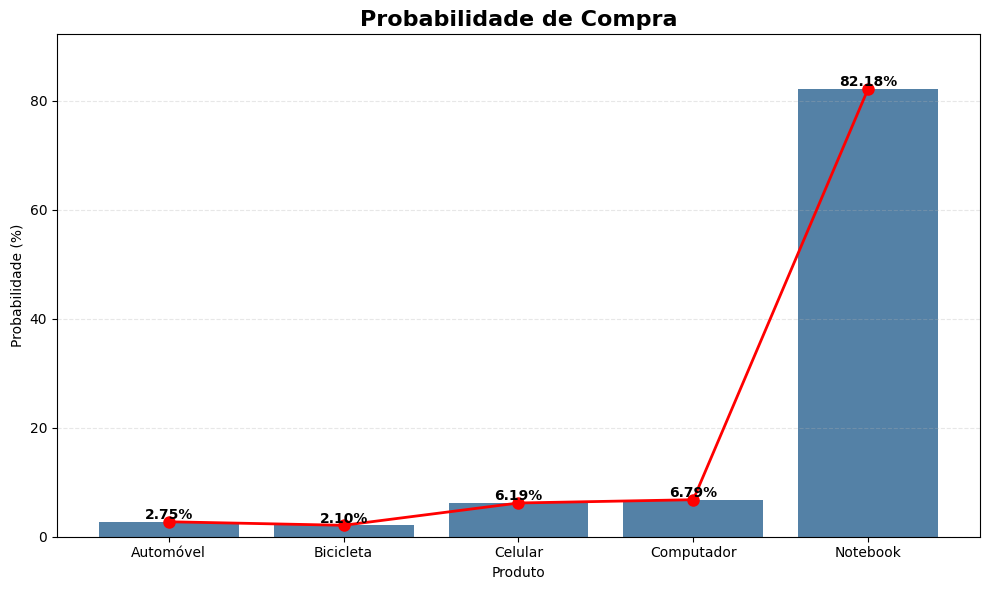

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

probabilidades_pct = probabilidades * 100

plt.figure(figsize=(10, 6))

sns.barplot(
    x=produtos,
    y=probabilidades_pct,
    color='steelblue'
)

plt.plot(
    range(len(produtos)),
    probabilidades_pct,
    color='red',
    marker='o',
    linewidth=2,
    markersize=8
)

for i, valor in enumerate(probabilidades_pct):
    plt.text(
        i,
        valor + 0.5,
        f'{valor:.2f}%',
        ha='center',
        fontweight='bold'
    )

plt.title(
    'Probabilidade de Compra',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Produto')
plt.ylabel('Probabilidade (%)')

plt.ylim(
    0,
    max(probabilidades_pct) + 10
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.show()


**SHAP**

In [51]:
!pip install -q shap

In [52]:
import shap
import matplotlib.pyplot as plt

In [53]:
modelo_xgb.fit(
    X_treino,
    y_treino_encoded
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [54]:
# ==========================================================
# SHAP - EXPLICAÇÃO DO MODELO
# ==========================================================

explainer = shap.TreeExplainer(modelo_xgb)

shap_values = explainer.shap_values(X_teste)

print("SHAP calculado com sucesso!")

SHAP calculado com sucesso!


/tmp/ipykernel_3156/162970595.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy glo

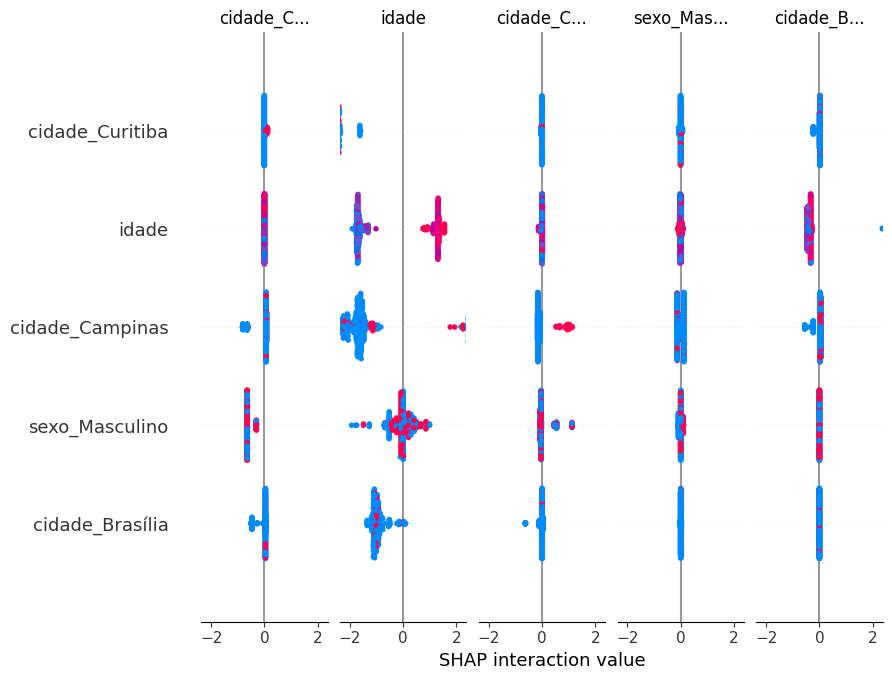

In [55]:
# ==========================================================
# IMPORTÂNCIA GLOBAL DAS VARIÁVEIS
# ==========================================================

shap.summary_plot(
    shap_values,
    X_teste,
    feature_names=X_teste.columns
)

/tmp/ipykernel_3156/3194412993.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


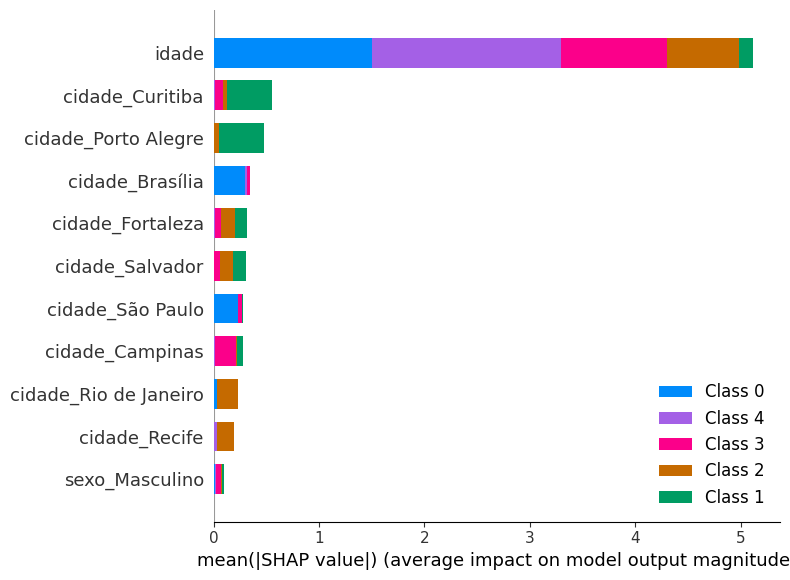

In [56]:
# ==========================================================
# IMPORTÂNCIA MÉDIA DAS VARIÁVEIS
# ==========================================================

shap.summary_plot(
    shap_values,
    X_teste,
    feature_names=X_teste.columns,
    plot_type="bar"
)

Analise do CLIENTE EM ESPECIFICO.

In [57]:
# ==========================================================
# CLIENTE PARA EXPLICAÇÃO
# ==========================================================

cliente = pd.DataFrame({
    'idade': [59],
    'sexo': ['Masculino'],
    'cidade': ['São Paulo']
})

cliente = pd.get_dummies(
    cliente,
    columns=['sexo', 'cidade'],
    drop_first=False
)

cliente = cliente.reindex(
    columns=X_treino.columns,
    fill_value=0
)

print(cliente)

   idade  sexo_Masculino  cidade_Brasília  cidade_Campinas  cidade_Curitiba  \
0     59            True                0                0                0   

   cidade_Fortaleza  cidade_Porto Alegre  cidade_Recife  \
0                 0                    0              0   

   cidade_Rio de Janeiro  cidade_Salvador  cidade_São Paulo  
0                      0                0              True  


In [59]:
# ==========================================================
# SHAP DO CLIENTE
# ==========================================================

shap_cliente = explainer.shap_values(cliente)

print(type(shap_cliente))

<class 'numpy.ndarray'>


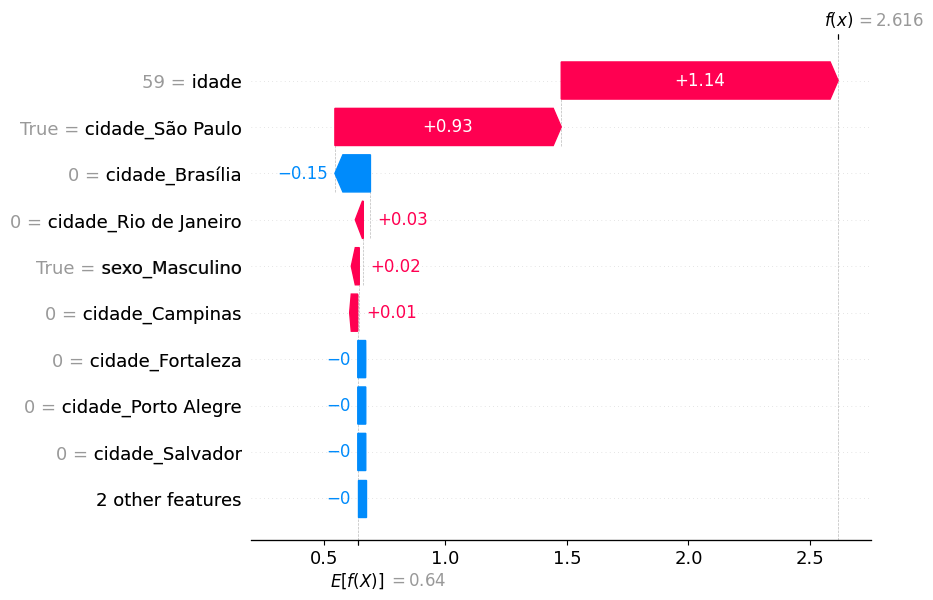

In [60]:
# ==========================================================
# EXPLICAÇÃO - AUTOMÓVEL
# ==========================================================

classe_automovel = list(le.classes_).index("Automóvel")

shap.plots.waterfall(
    shap.Explanation(
        values=shap_cliente[0, :, classe_automovel],
        base_values=explainer.expected_value[classe_automovel],
        data=cliente.iloc[0].values,
        feature_names=cliente.columns
    )
)

In [61]:
clientes = pd.DataFrame({
    'idade': [20, 35, 59],
    'sexo': ['Masculino', 'Masculino', 'Masculino'],
    'cidade': ['São Paulo', 'São Paulo', 'São Paulo']
})

In [62]:
clientes = pd.get_dummies(
    clientes,
    columns=['sexo', 'cidade'],
    drop_first=False
)

clientes = clientes.reindex(
    columns=X_treino.columns,
    fill_value=0
)

In [63]:
probabilidades = modelo_xgb.predict_proba(clientes)

for i, prob in enumerate(probabilidades):

    print("\nCliente:", i + 1)

    for produto, p in zip(le.classes_, prob):
        print(f"{produto:<15} {p:.2%}")


Cliente: 1
Automóvel       14.44%
Bicicleta       5.74%
Celular         73.42%
Computador      3.39%
Notebook        3.02%

Cliente: 2
Automóvel       11.75%
Bicicleta       2.76%
Celular         5.63%
Computador      5.17%
Notebook        74.69%

Cliente: 3
Automóvel       91.70%
Bicicleta       1.55%
Celular         3.40%
Computador      2.67%
Notebook        0.67%
